# 03b Promotion events and spike adjustment

Optional extension to notebook 03, for after the session. Runs in about a minute. First a descriptive look at what happens around promotions. Then a test of whether separating the temporary promotion spike from baseline demand improves the forecast.

Information tiers are as in 03: the planned scenario uses realized promotion flags for the first `PLAN_WEEKS` weeks as a stand-in for a promotion plan; the oracle uses them for all 14 weeks. No price enters these models.


In [1]:
import os
import sys
import warnings

if "google.colab" in sys.modules:
    !git clone -q https://github.com/tackes/time-series-forecasting-bootcamp
    %cd time-series-forecasting-bootcamp
    %pip install -q statsforecast==2.1.1 mlforecast==1.1.0 utilsforecast==0.2.17 lightgbm==4.7.0 catboost==1.2.10
elif not os.path.exists("shared"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore")

In [2]:
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from mlforecast import MLForecast
from mlforecast.target_transforms import LocalStandardScaler

from shared.prepare_data import load_panel, H, FREQ, ALL_CUTOFFS, DEV_CUTOFFS, TEST_CUTOFF
from shared.features import LAGS, LAG_TRANSFORMS, DATE_FEATURES, LGB_PARAMS, future_promo, promo_features
from shared.evaluation import score
from shared.leaderboard import to_long, save_forecasts, load_forecasts, leaderboard, TIERS

panel = load_panel()
panel["promo"] = panel.is_promotional.astype(int)
actuals = panel[["unique_id", "ds", "y"]]
flags = panel[["unique_id", "ds", "promo"]]

## Event study

Event time 0 is the first week of a promotion episode (consecutive promotion weeks). Sales are divided by the series' average over the 8 weeks before the episode.

To keep events from overlapping, we use only episodes with no other promotion in the 8 weeks before onset and the 6 weeks after the end. This is descriptive, not causal: promotions are chosen, not randomly assigned. It uses data through the final cutoff only, and most isolated episodes are a single week, so it says little about multi-week promotions.

In [3]:
hist = panel[panel.ds <= TEST_CUTOFF].reset_index(drop=True)
onset = (hist.promo == 1) & (hist.groupby("unique_id").promo.shift(1).fillna(0) == 0)
hist["episode"] = onset.groupby(hist.unique_id).cumsum().where(hist.promo == 1)

episodes = hist[hist.promo == 1].groupby(["unique_id", "episode"]).agg(start=("ds", "min"), end=("ds", "max"), length=("ds", "size")).reset_index()
episodes["prev_end"] = episodes.groupby("unique_id").end.shift(1)
episodes["next_start"] = episodes.groupby("unique_id").start.shift(-1)
isolated = episodes[
    (episodes.start - episodes.prev_end > pd.Timedelta(weeks=8)).fillna(True)
    & (episodes.next_start - episodes.end > pd.Timedelta(weeks=6)).fillna(True)
]
print(f"{len(episodes):,} promotion episodes, {len(isolated):,} isolated")
isolated.length.clip(upper=4).value_counts().sort_index().rename("episodes by length (4 = 4+)")

15,342 promotion episodes, 784 isolated


length
1    721
2      7
3      2
4     54
Name: episodes by length (4 = 4+), dtype: int64

In [4]:
y_lookup = hist.set_index(["unique_id", "ds"]).y

rows = []
for e in isolated.itertuples():
    weeks = pd.date_range(e.start - pd.Timedelta(weeks=8), e.end + pd.Timedelta(weeks=6), freq=FREQ)
    y = y_lookup.reindex(pd.MultiIndex.from_product([[e.unique_id], weeks])).to_numpy()
    base = y[:8].mean()
    if np.isnan(y).any() or base <= 0:
        continue
    t = np.arange(-8, len(weeks) - 8)
    rows.append(pd.DataFrame({"event": e.Index, "t_start": t, "t_end": t - (e.length - 1), "ratio": y / base, "length": e.length}))
events = pd.concat(rows)
print(f"{events.event.nunique():,} events used")

758 events used


Sales relative to the pre-promotion baseline, by week since the episode started and by week since it ended. The line is the median across events; the band is the interquartile range.

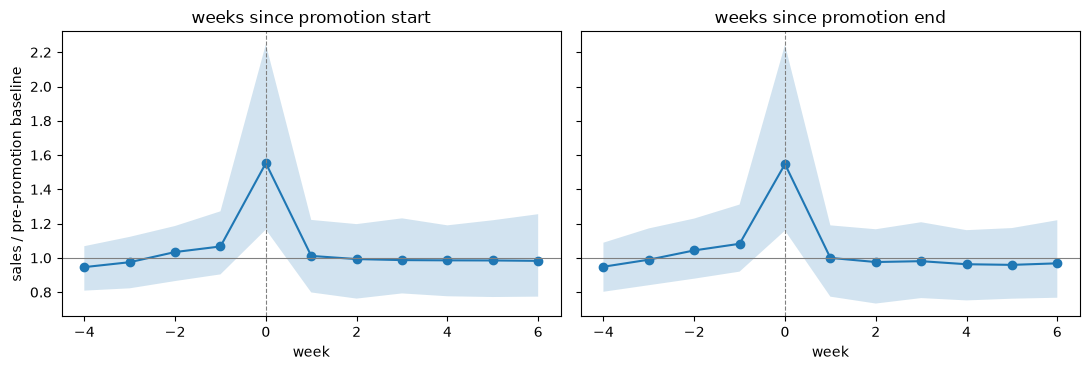

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, col, title in [(axes[0], "t_start", "weeks since promotion start"), (axes[1], "t_end", "weeks since promotion end")]:
    q = events[events[col].between(-4, 6)].groupby(col).ratio.quantile([0.25, 0.5, 0.75]).unstack()
    ax.plot(q.index, q[0.5], marker="o")
    ax.fill_between(q.index, q[0.25], q[0.75], alpha=0.2)
    ax.axhline(1, color="grey", lw=0.8)
    ax.axvline(0, color="grey", lw=0.8, ls="--")
    ax.set(title=title, xlabel="week")
axes[0].set_ylabel("sales / pre-promotion baseline")
plt.tight_layout()

In [6]:
table = events[events.t_end.between(-1, 4)].groupby("t_end").ratio.agg(median="median", mean="mean", events="size").round(2)
table.index.name = "weeks since end"
table

,median,mean,events
weeks since end,,,
-1,1.08,1.22,758
0,1.55,2.06,758
1,1.00,1.10,758
2,0.98,1.05,758
3,0.98,1.08,758
4,0.96,1.06,758


Week 0 on the right is the last promotion week; weeks 1 and later are after it. A median ratio below 1 in weeks 1 and 2 would say promotions borrow demand from the following weeks; a ratio near 1 would say they don't. The mean is pulled up by a few very large spikes, which is why the plot shows the median. The same medians by episode length:

In [7]:
events[events.t_end.between(0, 3)].assign(length=lambda d: d.length.clip(upper=3)).groupby(["length", "t_end"]).ratio.median().unstack().round(2)

t_end,0,1,2,3
length,,,,
1,1.57,1.00,0.98,0.97
2,2.47,1.93,1.24,1.01
3,1.29,0.95,0.90,1.00


## Spike adjustment

A promotion week is a temporary spike. If it feeds a lag feature, the model sees "demand is high" for the following weeks, and on a recursive forecast the spike can be carried forward as if it were a level shift. The idea is to forecast baseline demand with the spike removed, then put the promotion effect back on top.

At each cutoff, using only data up to the cutoff:

1. For each promotion week, the baseline is the mean of the non-promotion weeks among the 8 weeks before it (carried forward if there are none). `y_adj` is `y` with every promotion week replaced by its baseline.
2. Each series gets an uplift `u = sum(y) / sum(baseline)` over its promotion weeks, clipped to [0.5, 5]. Series with fewer than 3 promotion weeks use the portfolio uplift.
3. LightGBM is trained on `y_adj` (still scaled per series). Its forecast is the baseline forecast.
4. The final forecast is `baseline_forecast * u` in weeks the scenario has a promotion, and `baseline_forecast` otherwise.

`lgbm_adj` uses `y_adj` with the 02 features. `lgbm_adj_calendar` also gives the model promotion-calendar features (promotion one and two weeks ago, weeks since the last promotion, the share of the last 13 weeks on promotion) so it can learn a post-promotion dip in the baseline.

In [8]:
def adjust_spikes(train):
    """Return y_adj and a per-series uplift, from data up to the cutoff only."""
    train = train.sort_values(["unique_id", "ds"]).reset_index(drop=True)
    non_promo = train.y.where(train.promo == 0)
    baseline = non_promo.groupby(train.unique_id).transform(lambda s: s.shift(1).rolling(8, min_periods=1).mean())
    baseline = baseline.groupby(train.unique_id).ffill().fillna(train.y)
    train["y_adj"] = train.y.where(train.promo == 0, baseline)

    promo_weeks = train[train.promo == 1].assign(baseline=baseline[train.promo == 1])
    totals = promo_weeks.groupby("unique_id").agg(y=("y", "sum"), baseline=("baseline", "sum"), n=("y", "size"))
    portfolio = totals.y.sum() / totals.baseline.sum()
    uplift = (totals.y / totals.baseline).clip(0.5, 5).where(totals.n >= 3, portfolio)
    return train, uplift.reindex(train.unique_id.unique()).fillna(portfolio)

In [9]:
def make_model(name):
    return MLForecast(
        models={name: lgb.LGBMRegressor(**LGB_PARAMS)},
        freq=FREQ,
        lags=LAGS,
        lag_transforms=LAG_TRANSFORMS,
        date_features=DATE_FEATURES,
        target_transforms=[LocalStandardScaler()],
        num_threads=1,
    )

PLAN_WEEKS = 4
scenarios = {"planned": ("planned_scenario", PLAN_WEEKS), "oracle": ("oracle", H)}
calendar_cols = ["promo_lag1", "promo_lag2", "promo_freq_13", "weeks_since_promo"]

mlf_adj = make_model("lgbm_adj")
mlf_adj_calendar = make_model("lgbm_adj_calendar")
forecasts = []

for cutoff in ALL_CUTOFFS:
    history = actuals[actuals.ds <= cutoff]
    train, uplift = adjust_spikes(history.merge(flags, on=["unique_id", "ds"]))
    adjusted = train[["unique_id", "ds", "y_adj"]].rename(columns={"y_adj": "y"})

    mlf_adj.fit(adjusted)
    base_forecast = mlf_adj.predict(H)

    for scenario, (tier, plan_weeks) in scenarios.items():
        future = future_promo(flags, cutoff, plan_weeks)
        frame = promo_features(pd.concat([flags[flags.ds <= cutoff], future]))
        past, future = frame[frame.ds <= cutoff], frame[frame.ds > cutoff]

        mlf_adj_calendar.fit(adjusted.merge(past[["unique_id", "ds"] + calendar_cols], on=["unique_id", "ds"]), static_features=[])
        calendar_forecast = mlf_adj_calendar.predict(H, X_df=future[["unique_id", "ds"] + calendar_cols])

        for name, base in [("lgbm_adj", base_forecast), ("lgbm_adj_calendar", calendar_forecast)]:
            out = base.merge(future[["unique_id", "ds", "promo"]], on=["unique_id", "ds"])
            factor = np.where(out.promo == 1, out.unique_id.map(uplift), 1)
            out[f"{name}_{scenario}"] = out[name] * factor
            forecasts.append(to_long(out[["unique_id", "ds", f"{name}_{scenario}"]], cutoff, "03b_promotion_spikes", tier))

forecasts = pd.concat(forecasts)

## Results

Compared with the baseline and with the 03 promotion models of the same tier. Rows every model forecasts; development origins first.

In [10]:
reference = load_forecasts(["02_ml_baseline", "03_exogenous"])
reference = reference[reference.model.isin(["lgbm_baseline", "lgbm_promo_planned", "lgbm_promo_calendar_planned", "lgbm_promo_oracle", "lgbm_promo_calendar_oracle"])]
columns = ["model", "coverage", "wape", "bias", "mean_rmsse", "median_rmsse", "apc", "apc_median"]
combined = pd.concat([reference, forecasts])

leaderboard(combined[combined.information_tier != "oracle"], actuals, scope="dev")[columns].round(3)

,model,coverage,wape,bias,mean_rmsse,median_rmsse,apc,apc_median
0,lgbm_baseline,1.0,0.449,0.139,1.865,0.921,0.136,0.149
1,lgbm_adj_planned,1.0,0.379,-0.118,1.736,0.858,0.208,0.218
2,lgbm_adj_calendar_planned,1.0,0.380,-0.110,1.741,0.859,0.203,0.214
3,lgbm_promo_calendar_planned,1.0,0.381,-0.030,1.737,0.841,0.221,0.241
4,lgbm_promo_planned,1.0,0.403,0.051,1.745,0.856,0.168,0.199


In [11]:
leaderboard(combined[combined.information_tier != "planned_scenario"], actuals, scope="dev")[columns].round(3)

,model,coverage,wape,bias,mean_rmsse,median_rmsse,apc,apc_median
0,lgbm_baseline,1.0,0.449,0.139,1.865,0.921,0.137,0.149
1,lgbm_adj_oracle,1.0,0.331,0.013,1.647,0.795,0.120,0.155
2,lgbm_adj_calendar_oracle,1.0,0.334,0.017,1.655,0.796,0.118,0.151
3,lgbm_promo_calendar_oracle,1.0,0.352,0.077,1.671,0.794,0.136,0.168
4,lgbm_promo_oracle,1.0,0.415,0.143,1.746,0.858,0.133,0.158


### Promotion and non-promotion weeks

Target weeks split by whether the item was on promotion that week (used only to slice the results). Bias shows whether the spike is under- or over-forecast.

In [12]:
planned = combined[combined.information_tier != "oracle"]
rows = planned[planned.cutoff.isin(DEV_CUTOFFS)].merge(flags.rename(columns={"promo": "target_promo"}), on=["unique_id", "ds"])
score(rows, actuals, by=["target_promo"], rmsse=False).pivot(index="model", columns="target_promo", values=["wape", "bias"]).round(3)

wape          bias       
target_promo                     0      1      0      1
model                                                  
lgbm_adj_calendar_planned    0.335  0.421  0.059 -0.266
lgbm_adj_planned             0.329  0.425  0.048 -0.271
lgbm_baseline                0.576  0.332  0.409 -0.111
lgbm_promo_calendar_planned  0.396  0.368  0.156 -0.202
lgbm_promo_planned           0.460  0.350  0.243 -0.126

### Reading the result

- Isolated promotions lift sales by a median of 55% in the last promotion week. Sales are back at the baseline the week after (median 1.00, then 0.98), so there is little sign of a post-promotion dip.
- With a four-week plan, spike adjustment matches the promotion-calendar model on development WAPE (0.379 against 0.381) but underforecasts more (bias -0.118 against -0.030).
- With all promotions known (oracle) it is better: 0.331 against 0.352.
- The gain is in non-promotion weeks (WAPE 0.329 against 0.396), where spikes no longer inflate the lags. Promotion weeks get worse (0.425 against 0.368): one uplift per series underforecasts them (bias -0.27).

In [13]:
save_forecasts(forecasts, "03b_promotion_spikes")